# 05. A second experiment: Hillstrom email test (short sanity check)

**The question this notebook answers:** does the same toolkit work on a *different* experiment,
one that has a real pre-experiment metric, and does CUPED help there?

The Hillstrom MineThatData email test has 64,000 customers split roughly into thirds: a
men's-merchandise email, a women's-merchandise email, and no email (control). The `history`
column is each customer's spend in the previous 12 months, measured *before* the email, which is
the textbook CUPED covariate. Outcomes are `visit`, `conversion` and `spend`.

This notebook is deliberately short. It is here to show the toolkit run on real data from a
second source, and to say plainly where it did **not** help.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from expkit import config, data, nb
from expkit.inference import compare_proportions, compare_samples
from expkit.report import n_
from expkit.srm import srm_test

ctx = nb.load()
R, con = ctx.results, ctx.con
H = R["cuped"]["hillstrom"]
ctx.banner()

> Data: **Criteo Uplift v2.1**. Pipeline numbers are read from `docs/results/results.json` (written by `expkit run-all` at code commit `41db89a`) and match `docs/RESULTS.md`. Seed 42.

## 1. The data and the sample ratio check

The arm summary comes from `sql/08_hillstrom_summary.sql`. Here the design is an equal three-way
split, so the SRM check compares the counts with 1/3 each.

In [2]:
summ = data.run_sql(con, "08_hillstrom_summary.sql")
df = con.execute(
    "SELECT segment, treatment, history, recency, visit, conversion, spend FROM hillstrom ORDER BY row_id"
).df()
display(
    pd.DataFrame(
        {
            "customers": summ["n"].map(n_),
            "visit rate": summ["visit_rate"].map(lambda v: f"{v:.2%}"),
            "conversion rate": summ["conversion_rate"].map(lambda v: f"{v:.2%}"),
            "mean spend ($)": summ["mean_spend"].map(lambda v: f"{v:.3f}"),
            "mean prior spend ($)": summ["mean_history"].map(lambda v: f"{v:.1f}"),
        }
    ).set_index(summ["segment"])
)
srm = srm_test([int(v) for v in summ["n"]], [1, 1, 1])
ctx.check("SRM p-value", srm.p_value, H["srm_p_value"], rtol=1e-6)
nb.md(
    f"{n_(len(df))} customers. Sample ratio check against an equal three-way split: p = {srm.p_value:.4f}, "
    f"{'flagged' if srm.flagged else 'not flagged'} (alarm at p < 0.001)."
)

,customers,visit rate,conversion rate,mean spend ($),mean prior spend ($)
segment,,,,,
Mens E-Mail,"21,307",18.28%,1.25%,1.423,242.8
No E-Mail,"21,306",10.62%,0.57%,0.653,240.9
Womens E-Mail,"21,387",15.14%,0.88%,1.077,242.5


- Check: SRM p-value: recomputed `0.903693`, pipeline `0.903693` (matches)

64,000 customers. Sample ratio check against an equal three-way split: p = 0.9037, not flagged (alarm at p < 0.001).

## 2. Lift of each email against no email

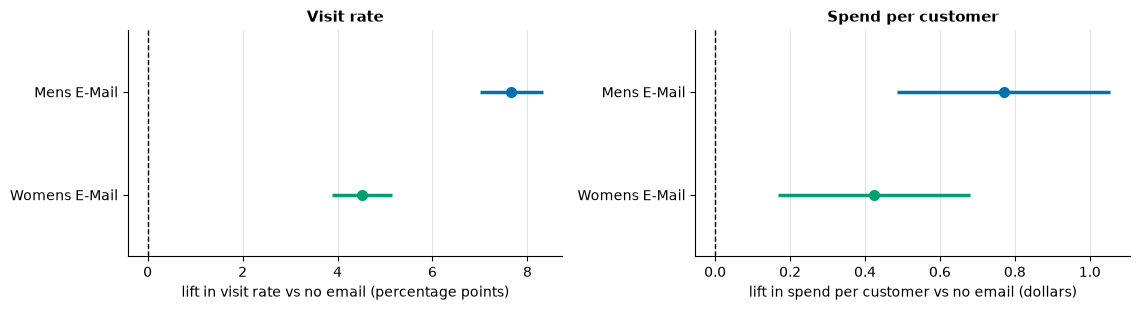

Visit lifts: Mens E-Mail +7.66 pp (+7.00 to +8.32); Womens E-Mail +4.52 pp (+3.89 to +5.16). Spend lifts: Mens E-Mail $+0.77 ($+0.49 to $+1.05); Womens E-Mail $+0.42 ($+0.17 to $+0.68).

In [3]:
ctl = df[df["segment"] == "No E-Mail"]
arms = [s for s in summ["segment"] if s != "No E-Mail"]
vis_rows, spend_rows = [], []
for arm, color in zip(arms, (nb.BLUE, nb.GREEN, nb.ORANGE)):
    a = df[df["segment"] == arm]
    v = compare_proportions(int(a["visit"].sum()), len(a), int(ctl["visit"].sum()), len(ctl))
    s = compare_samples(a["spend"].to_numpy(), ctl["spend"].to_numpy())
    vis_rows.append({"label": arm, "est": v.diff, "lo": v.ci_low, "hi": v.ci_high, "color": color})
    spend_rows.append(
        {"label": arm, "est": s.diff, "lo": s.ci_low, "hi": s.ci_high, "color": color}
    )

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 3.2))
nb.forest(a, vis_rows, xlabel="lift in visit rate vs no email (percentage points)", ref=0.0)
a.set_title("Visit rate")
nb.forest(
    b, spend_rows, scale=1.0, xlabel="lift in spend per customer vs no email (dollars)", ref=0.0
)
b.set_title("Spend per customer")
fig.tight_layout()
ctx.savefig(fig, "hillstrom_lifts")
nb.md(
    "Visit lifts: "
    + "; ".join(
        f"{r['label']} {r['est'] * 100:+.2f} pp ({r['lo'] * 100:+.2f} to {r['hi'] * 100:+.2f})"
        for r in vis_rows
    )
    + ". Spend lifts: "
    + "; ".join(
        f"{r['label']} ${r['est']:+.2f} (${r['lo']:+.2f} to ${r['hi']:+.2f})" for r in spend_rows
    )
    + "."
)

## 3. CUPED with a genuine pre-period covariate

CUPED works when the covariate is strongly correlated with the outcome. The fraction of variance
it can remove is about the squared correlation. So the first thing to look at is how well prior
spend predicts spend during the test.

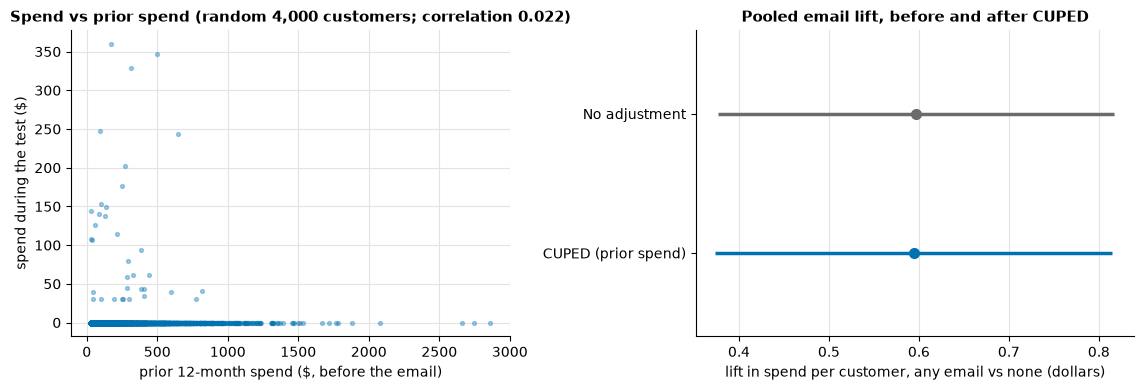

,lift ($/customer),standard error,95% interval
No adjustment,0.597,0.1126,0.376 to 0.817
CUPED,0.594,0.1125,0.374 to 0.815


Prior spend and spend during the test have a correlation of only **0.022**, so the most CUPED could remove is about 0.05% of the variance. Measured variance reduction: **0.03%**; users needed with CUPED: 99.97% of the unadjusted number. Only 578 of 64,000 customers (0.90%) spent anything, so spend is mostly zeros and prior spend says little about who happens to buy this week.

In [4]:
rng = np.random.default_rng(config.SEED)
shown = df.iloc[rng.choice(len(df), size=min(4000, len(df)), replace=False)]
buyers = int((df["spend"] > 0).sum())
r = H["corr_spend_history"]

fig, (a, b) = plt.subplots(1, 2, figsize=(11.5, 4))
a.scatter(shown["history"], shown["spend"], s=8, color=nb.BLUE, alpha=0.35)
a.set_xlabel("prior 12-month spend ($, before the email)")
a.set_ylabel("spend during the test ($)")
a.set_title(f"Spend vs prior spend (random {n_(len(shown))} customers; correlation {r:.3f})")

raw, cu = H["raw"], H["cuped"]
nb.forest(
    b,
    [
        {
            "label": "No adjustment",
            "est": raw["diff"],
            "lo": raw["ci_low"],
            "hi": raw["ci_high"],
            "color": nb.GREY,
        },
        {
            "label": "CUPED (prior spend)",
            "est": cu["diff"],
            "lo": cu["ci_low"],
            "hi": cu["ci_high"],
            "color": nb.BLUE,
        },
    ],
    scale=1.0,
    xlabel="lift in spend per customer, any email vs none (dollars)",
)
b.set_title("Pooled email lift, before and after CUPED")
fig.tight_layout()
ctx.savefig(fig, "hillstrom_cuped")

vr = cu["variance_reduction"]
display(
    pd.DataFrame(
        {
            "lift ($/customer)": [f"{raw['diff']:.3f}", f"{cu['diff']:.3f}"],
            "standard error": [f"{raw['se']:.4f}", f"{cu['se']:.4f}"],
            "95% interval": [
                f"{raw['ci_low']:.3f} to {raw['ci_high']:.3f}",
                f"{cu['ci_low']:.3f} to {cu['ci_high']:.3f}",
            ],
        },
        index=["No adjustment", "CUPED"],
    )
)
nb.md(
    f"Prior spend and spend during the test have a correlation of only **{r:.3f}**, so the most CUPED "
    f"could remove is about {r**2:.2%} of the variance. Measured variance reduction: **{vr:.2%}**; "
    f"users needed with CUPED: {cu['sample_size_ratio']:.2%} of the unadjusted number. Only "
    f"{buyers:,} of {n_(len(df))} customers ({buyers / len(df):.2%}) spent anything, so spend is mostly zeros "
    f"and prior spend says little about who happens to buy this week."
)

## Summary

In [5]:
H_criteo = R["cuped"]["criteo"]
nb.notes(
    "What this means",
    [
        f"The toolkit runs unchanged on a second, differently shaped experiment (three arms, a dollar "
        f"outcome). The sample ratio check {'passes' if not srm.flagged else 'FAILS'} (p = {srm.p_value:.3f}).",
        f"Visit rate against no email: {vis_rows[0]['label']} {vis_rows[0]['est'] * 100:+.2f} pp, "
        f"{vis_rows[1]['label']} {vis_rows[1]['est'] * 100:+.2f} pp.",
        (
            f"CUPED did **not** help here: variance reduction {vr:.2%}, because prior spend is almost "
            f"unrelated to spend during the test (correlation {r:.3f})."
            if vr < 0.01
            else f"CUPED reduced the variance by {vr:.2%} (correlation {r:.3f})."
        )
        + " CUPED is only as good as its covariate.",
    ],
)
nb.notes(
    "What is weak",
    [
        f"Do not claim CUPED improved this analysis unless the number above says so ({vr:.2%} here). "
        f"The {H_criteo['cupac']['variance_reduction']:.1%} variance reduction in notebook 03 comes from the "
        "Criteo experiment with a model-based covariate, not from this data.",
        "Hillstrom is an old (2008), single-retailer test. It checks that the code runs on real, "
        "differently shaped data. It is not a second proof of the ad-targeting findings.",
        "Only one covariate (prior spend) was used for CUPED, as fixed in the pipeline before the "
        "results were seen. Other columns such as recency were not tried.",
        f"Spend is zero for {1 - buyers / len(df):.1%} of customers and heavily skewed, so "
        "normal-approximation intervals for spend are less reliable than the ones for rates.",
    ],
)

### What this means

- The toolkit runs unchanged on a second, differently shaped experiment (three arms, a dollar outcome). The sample ratio check passes (p = 0.904).
- Visit rate against no email: Mens E-Mail +7.66 pp, Womens E-Mail +4.52 pp.
- CUPED did **not** help here: variance reduction 0.03%, because prior spend is almost unrelated to spend during the test (correlation 0.022). CUPED is only as good as its covariate.

### What is weak

- Do not claim CUPED improved this analysis unless the number above says so (0.03% here). The 30.5% variance reduction in notebook 03 comes from the Criteo experiment with a model-based covariate, not from this data.
- Hillstrom is an old (2008), single-retailer test. It checks that the code runs on real, differently shaped data. It is not a second proof of the ad-targeting findings.
- Only one covariate (prior spend) was used for CUPED, as fixed in the pipeline before the results were seen. Other columns such as recency were not tried.
- Spend is zero for 99.1% of customers and heavily skewed, so normal-approximation intervals for spend are less reliable than the ones for rates.